# Stochastické algoritmy

*Nad rámec cvičení — kapitola 9 skripta.*

---

Všechny ostatní sešity používají náhodu k **odhadování**: chceme číslo (integrál, pravděpodobnost, střední hodnotu) a náhodné vzorky jsou cesta k němu. Tenhle sešit je o něčem jiném — o náhodě jako **součásti algoritmu**, který má vydat odpověď na úplně nepravděpodobnostní otázku.

- **Určování prvočíselnosti**: randomizovaný algoritmus, který se smí mýlit, ale jen jedním směrem a jen s pravděpodobností, kterou si zvolíte
- **Simulované žíhání**: jak najít dobré řešení optimalizační úlohy tím, že občas schválně uděláte krok k horšímu

Společné je to, že náhoda nemodeluje nic ve světě. Je to **nástroj uvnitř výpočtu**.

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky

## 1. Je to prvočíslo?

Zkusmé dělení do $\sqrt n$ je spolehlivé, ale pro čísla o stovkách cifer (což jsou přesně ta, co potřebuje RSA) beznadějně pomalé. Randomizovaný přístup vymění jistotu za rychlost.

### Fermatův test a proč nestačí

Malá Fermatova věta: je-li $n$ prvočíslo a $1 < a < n$, pak

$$a^{n-1} \equiv 1 \pmod n.$$

Obrátíme to: najdeme-li $a$, pro které rovnost **neplatí**, je $n$ určitě složené. Takovému $a$ se říká **svědek** složenosti. Když rovnost platí, $n$ je „pravděpodobně prvočíslo".

Jenže existují složená čísla, pro která rovnost platí pro **všechna** $a$ nesoudělná s $n$ — **Carmichaelova čísla**, nejmenší je $561 = 3\cdot 11\cdot 17$. Fermatův test je u nich bezmocný.

In [2]:
def fermat_test(n, pokusu=500):
    """Fermatův test. Vrací podíl SVĚDKŮ mezi bázemi NESOUDĚLNÝMI s n.

    Omezení na nesoudělné báze je podstatné: báze se společným dělitelem prozradí n
    triviálně (stačí Euklidův algoritmus) a o síle Fermatova testu nic neříká.
    """
    svedku = zkousenych = 0
    for _ in range(pokusu):
        a = random.randrange(2, n - 1)
        if math.gcd(a, n) != 1:
            continue
        zkousenych += 1
        if pow(a, n - 1, n) != 1:
            svedku += 1
    return svedku / zkousenych, zkousenych


print(f"{'n':>9s} {'typ':>24s} {'nesoudělných bází':>18s} {'z nich svědků':>14s}")
for n, popis in ((97, "prvočíslo"), (561, "Carmichaelovo (3·11·17)"), (1105, "Carmichaelovo (5·13·17)"),
                 (1729, "Carmichaelovo (7·13·19)"), (1001, "složené (7·11·13)")):
    podil, zk = fermat_test(n)
    print(f"{n:>9d} {popis:>24s} {zk:>18d} {podil:>14.1%}")

        n                      typ  nesoudělných bází  z nich svědků
       97                prvočíslo                500           0.0%
      561  Carmichaelovo (3·11·17)                281           0.0%
     1105  Carmichaelovo (5·13·17)                350           0.0%
     1729  Carmichaelovo (7·13·19)                392           0.0%
     1001        složené (7·11·13)                355          88.5%


Běžné složené číslo (1001) prozradí skoro každá báze — svědků je kolem 90 %.

U Carmichaelových čísel je svědků **přesně nula**. Není to „málo", je to nic: každá báze nesoudělná s $n$ rovnost splní. Fermatův test je u nich bezmocný bez ohledu na to, kolikrát ho pustíte. A Carmichaelových čísel je nekonečně mnoho (Alford, Granville a Pomerance, 1994).

### Millerův–Rabinův test

Opravou je využít víc struktury. Zapišme $n - 1 = 2^s d$ s lichým $d$. Je-li $n$ liché prvočíslo, pak pro každé $a$ platí

$$a^d \equiv 1 \pmod n \qquad\text{nebo}\qquad a^{2^r d} \equiv -1 \pmod n \ \text{ pro nějaké } 0 \le r < s.$$

Důvod: $x^2 \equiv 1 \pmod n$ má u prvočísla jen řešení $x \equiv \pm 1$. U složeného $n$ existují i jiné odmocniny z jedničky, a právě ty test odhalí.

Klíčová vlastnost: pro **složené** $n$ je aspoň $3/4$ všech bází svědkem. Po $k$ nezávislých pokusech je pravděpodobnost chyby nejvýš $4^{-k}$ — a chyba je **jednostranná**: „složené" je vždy pravda, „prvočíslo" může být omyl.

In [3]:
def mr_svedek(n, a):
    """Je báze a svědkem složenosti n podle Millerova–Rabinova kritéria?"""
    d, s = n - 1, 0
    while d % 2 == 0:
        d //= 2
        s += 1
    x = pow(a, d, n)
    if x == 1 or x == n - 1:
        return False
    for _ in range(s - 1):
        x = x * x % n
        if x == n - 1:
            return False
    return True


def miller_rabin(n, k=20):
    """Millerův–Rabinův test. 'Složené' je jisté, 'prvočíslo' platí s pravděpodobností >= 1 - 4^-k."""
    if n < 2:
        return False
    for p in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37):
        if n % p == 0:
            return n == p
    return not any(mr_svedek(n, random.randrange(2, n - 1)) for _ in range(k))


def podil_svedku_mr(n, max_bazi=2000):
    """Podíl svědků mezi bázemi 2..n-2 (u složeného n má být aspoň 3/4)."""
    baze = range(2, min(n - 1, max_bazi + 2))
    return sum(mr_svedek(n, a) for a in baze) / len(baze)


print(f"{'n':>10s} {'typ':>24s} {'Fermat svědků':>14s} {'M-R svědků':>12s}")
for n, popis in ((561, "Carmichaelovo (3·11·17)"), (1105, "Carmichaelovo (5·13·17)"),
                 (1729, "Carmichaelovo (7·13·19)"), (1001, "složené (7·11·13)"),
                 (25326001, "silné pseudoprvočíslo*")):
    f_txt = f"{fermat_test(n)[0]:13.1%}" if n < 10**6 else f"{'—':>13s}"
    print(f"{n:>10d} {popis:>24s} {f_txt} {podil_svedku_mr(n):12.1%}")

print("\nmez z věty: u složeného n je svědkem aspoň 75 % bází — všechny řádky ji splňují")
print("* 25 326 001 projde Millerovým–Rabinovým testem pro báze 2, 3 i 5 zároveň")

         n                      typ  Fermat svědků   M-R svědků
       561  Carmichaelovo (3·11·17)          0.0%        98.6%
      1105  Carmichaelovo (5·13·17)          0.0%        97.5%
      1729  Carmichaelovo (7·13·19)          0.0%        90.7%
      1001        složené (7·11·13)         87.2%        99.2%
  25326001   silné pseudoprvočíslo*             —        86.5%

mez z věty: u složeného n je svědkem aspoň 75 % bází — všechny řádky ji splňují
* 25 326 001 projde Millerovým–Rabinovým testem pro báze 2, 3 i 5 zároveň


Carmichaelova čísla, která Fermatův test nepoznal, Miller–Rabin odhalí s přehledem — svědků je přes 75 %, přesně jak věta slibuje.

Teď to, kvůli čemu se randomizace dělá: rychlost.

In [4]:
def zkusmo(n):
    """Deterministické dělení do sqrt(n)."""
    if n < 2:
        return False
    if n % 2 == 0:
        return n == 2
    i = 3
    while i * i <= n:
        if n % i == 0:
            return False
        i += 2
    return True


print(f"{'prvočíslo':>18s} {'cifer':>6s} {'zkusmé dělení':>16s} {'Miller-Rabin':>14s}")
rychlost = None
for exp in (15, 25, 35, 45):
    n = 2 ** exp - 1
    while not miller_rabin(n):
        n -= 2
    t0 = time.perf_counter()
    miller_rabin(n, 20)
    t_mr = time.perf_counter() - t0
    if exp <= 35:                       # nad 35 bitů už bychom čekali moc dlouho
        t0 = time.perf_counter()
        zkusmo(n)
        t_zk = time.perf_counter() - t0
        rychlost = math.sqrt(n) / 2 / t_zk       # dělení za sekundu, změřeno
        zk = f"{t_zk * 1e3:13.1f} ms"
    else:
        zk = f"{'(neměřeno)':>16s}"
    print(f"{n:>18} {len(str(n)):>6d} {zk:>16s} {t_mr * 1e3:11.2f} ms")

t0 = time.perf_counter()
kandidat = random.randrange(2**511, 2**512) | 1
while not miller_rabin(kandidat, 25):
    kandidat += 2
t_hledani = time.perf_counter() - t0

print(f"\nnalezeno 512bitové prvočíslo ({len(str(kandidat))} cifer) za {t_hledani:.2f} s")
print(f"pravděpodobnost omylu nejvýš 4^-25 = {4.0 ** -25:.1e}")
let = math.sqrt(kandidat) / 2 / rychlost / (3600 * 24 * 365.25)
print(f"\nzkusmé dělení při naměřené rychlosti ({rychlost:,.0f} dělení/s)".replace(",", " "))
print(f"  by na něm trvalo řádově 10^{math.log10(let):.0f} let   (vesmír existuje 1.4·10^10 let)")

         prvočíslo  cifer    zkusmé dělení   Miller-Rabin
             32749      5           0.0 ms        0.02 ms
          33554393      8           0.1 ms        0.03 ms
       34359738337     11           5.8 ms        0.12 ms
    35184372088777     14       (neměřeno)        0.16 ms

nalezeno 512bitové prvočíslo (155 cifer) za 0.06 s
pravděpodobnost omylu nejvýš 4^-25 = 8.9e-16

zkusmé dělení při naměřené rychlosti (15 926 665 dělení/s)
  by na něm trvalo řádově 10^62 let   (vesmír existuje 1.4·10^10 let)


Poslední řádek je pointa celé randomizace: 512bitové prvočíslo najdeme za zlomek sekundy s pravděpodobností omylu kolem $10^{-15}$ — menší, než je šance na chybu hardwaru. Zkusmé dělení by na stejném čísle běželo déle, než existuje vesmír.

**Jednostranná chyba** je tu podstatná. Algoritmus nikdy neoznačí prvočíslo za složené. Může jen prohlásit složené číslo za prvočíslo, a tu pravděpodobnost si libovolně srazíme zvýšením $k$. Takovým algoritmům se říká **Monte Carlo algoritmy** — na rozdíl od **Las Vegas** algoritmů, které vracejí vždy správnou odpověď, ale doba běhu je náhodná.

## 2. Simulované žíhání

Druhý způsob, jak náhodu použít uvnitř algoritmu: **optimalizace**.

Úloha obchodního cestujícího: $n$ měst, najít nejkratší okružní cestu přes všechna. Počet možností je $(n-1)!/2$, tedy pro 60 měst asi $10^{80}$ — všechny vyzkoušet nelze.

### Proč nestačí jít pořád z kopce

Přirozený nápad: začni náhodnou cestou a opakovaně dělej malé změny, které ji zkrátí. Tomu se říká **horolezecký algoritmus**. Zasekne se v prvním **lokálním** minimu — konfiguraci, kterou žádná malá změna nezlepší, i když globální optimum je jinde.

### Metropolisovo kritérium

Simulované žíhání lokálním minimům uteče tím, že **občas schválně přijme zhoršení**. Změnu o $\Delta E$ přijmeme s pravděpodobností

$$P = \begin{cases} 1, & \Delta E \le 0 \quad\text{(zlepšení přijmeme vždy)},\\[1mm] e^{-\Delta E / T}, & \Delta E > 0 \quad\text{(zhoršení jen někdy)}. \end{cases}$$

Parametr $T$ je **teplota**. Při vysoké $T$ se přijme skoro všechno a algoritmus bloudí; při nízké $T$ se chová jako horolezec. Postupné chlazení je ta metafora žíhání kovu: horká fáze prozkoumává, chladná dolaďuje.

Pravděpodobnost přijetí je přesně místo, kde je potřeba $\gamma \sim R(0,1)$ — přijmeme, když $\gamma < e^{-\Delta E/T}$.

In [5]:
def nahodna_mesta(n):
    return [(random.random(), random.random()) for _ in range(n)]


def delka(cesta, mesta):
    return sum(math.dist(mesta[cesta[i]], mesta[cesta[i - 1]]) for i in range(len(cesta)))


def delta_2opt(cesta, mesta, i, j):
    """O kolik se změní délka, když se obrátí úsek cesta[i:j+1]. Stačí 4 vzdálenosti."""
    n = len(cesta)
    a, b = mesta[cesta[i - 1]], mesta[cesta[i]]
    c, d = mesta[cesta[j]], mesta[cesta[(j + 1) % n]]
    return (math.dist(a, c) + math.dist(b, d)) - (math.dist(a, b) + math.dist(c, d))


def vychozi_teplota(n):
    """Zhruba polovina typické hrany dobré cesty.

    Pro n bodů rovnoměrně ve čtverci měří optimální cesta asi 0.7*sqrt(n),
    takže jedna hrana kolem 0.7/sqrt(n). Teplota řádu jedné hrany znamená,
    že se na začátku přijímají i citelná zhoršení.
    """
    return 0.5 * 0.7 / math.sqrt(n)


def zihani(mesta, kroku=300_000, T0=None, T1=1e-3, horolezec=False):
    """Simulované žíhání s 2-opt tahy. horolezec=True přijímá jen zlepšení."""
    n = len(mesta)
    T0 = vychozi_teplota(n) if T0 is None else T0
    cesta = list(range(n))
    random.shuffle(cesta)
    d = delka(cesta, mesta)
    nej, nej_cesta = d, cesta[:]
    historie, teploty = [], []
    for krok in range(kroku):
        T = T0 * (T1 / T0) ** (krok / kroku)        # geometrické chlazení
        i = random.randrange(1, n - 1)
        j = random.randrange(i + 1, n)
        dE = delta_2opt(cesta, mesta, i, j)
        if dE <= 0 or (not horolezec and random.random() < math.exp(-dE / T)):
            cesta[i:j + 1] = reversed(cesta[i:j + 1])
            d += dE
            if d < nej:
                nej, nej_cesta = d, cesta[:]
        if krok % 500 == 0:
            historie.append(d)
            teploty.append(T)
    return nej_cesta, nej, historie, teploty


N_MEST, KROKU, BEHU = 60, 300_000, 6
mesta = nahodna_mesta(N_MEST)
pocatecni = list(range(N_MEST))
random.shuffle(pocatecni)

# poctivé srovnání: stejný počet kroků i běhů, porovnáváme průměry
t0 = time.perf_counter()
vysl_zih = [zihani(mesta, kroku=KROKU) for _ in range(BEHU)]
t_zih = (time.perf_counter() - t0) / BEHU
vysl_hor = [zihani(mesta, kroku=KROKU, horolezec=True)[1] for _ in range(BEHU)]

d_zih = [v[1] for v in vysl_zih]
cesta_zih, _, hist_zih, teploty = min(vysl_zih, key=lambda v: v[1])

print(f"{N_MEST} měst, {KROKU:,} kroků na běh, {BEHU} běhů od každé metody".replace(",", " "))
print(f"výchozí teplota T0 = {vychozi_teplota(N_MEST):.4f}\n")
print(f"{'metoda':22s} {'průměr':>9s} {'nejlepší':>10s} {'nejhorší':>10s}")
print(f"{'náhodná cesta':22s} {delka(pocatecni, mesta):9.3f}")
print(f"{'horolezec':22s} {sum(vysl_hor) / BEHU:9.3f} {min(vysl_hor):10.3f} {max(vysl_hor):10.3f}")
print(f"{'simulované žíhání':22s} {sum(d_zih) / BEHU:9.3f} {min(d_zih):10.3f} {max(d_zih):10.3f}")
print(f"\nžíhání je v průměru o {(sum(vysl_hor) / sum(d_zih) - 1):.1%} lepší,")
print(f"a i jeho nejhorší běh ({max(d_zih):.3f}) překonal nejlepší běh horolezce ({min(vysl_hor):.3f}).")
print(f"čas na jeden běh žíhání: {t_zih:.2f} s")

60 měst  300 000 kroků na běh  6 běhů od každé metody
výchozí teplota T0 = 0.0452

metoda                    průměr   nejlepší   nejhorší
náhodná cesta             30.173
horolezec                  6.773      6.489      6.971
simulované žíhání          6.461      6.388      6.532

žíhání je v průměru o 4.8% lepší,
a i jeho nejhorší běh (6.532) překonal nejlepší běh horolezce (6.489).
čas na jeden běh žíhání: 0.24 s


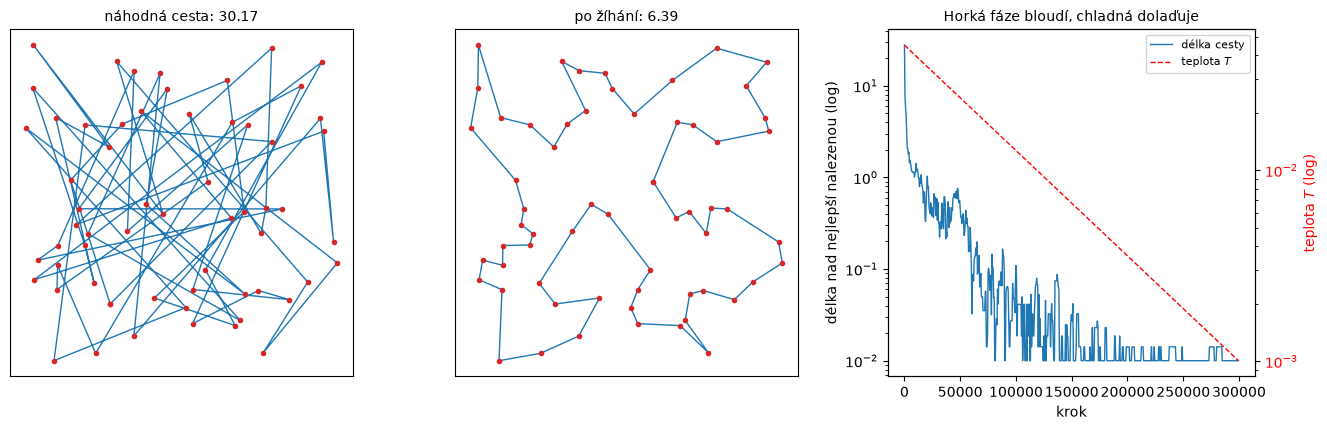

In [6]:
def nakresli(ax, cesta, mesta, nazev):
    xs = [mesta[k][0] for k in cesta] + [mesta[cesta[0]][0]]
    ys = [mesta[k][1] for k in cesta] + [mesta[cesta[0]][1]]
    ax.plot(xs, ys, "-", lw=1, color="tab:blue")
    ax.plot(xs, ys, "o", ms=3, color="tab:red")
    ax.set_title(nazev, fontsize=10)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])


fig = plt.figure(figsize=(13.5, 4.4))
ax = fig.add_subplot(1, 3, 1)
nakresli(ax, pocatecni, mesta, f"náhodná cesta: {delka(pocatecni, mesta):.2f}")
ax = fig.add_subplot(1, 3, 2)
nakresli(ax, cesta_zih, mesta, f"po žíhání: {min(d_zih):.2f}")

ax = fig.add_subplot(1, 3, 3)
kroky = [500 * i for i in range(len(hist_zih))]
ax.semilogy(kroky, [h - min(d_zih) + 1e-2 for h in hist_zih], lw=1, label="délka cesty")
ax.set_xlabel("krok")
ax.set_ylabel("délka nad nejlepší nalezenou (log)")
ax.set_title("Horká fáze bloudí, chladná dolaďuje", fontsize=10)
ax2 = ax.twinx()
ax2.semilogy(kroky, teploty, "r--", lw=1, label="teplota $T$")
ax2.set_ylabel("teplota $T$ (log)", color="r")
ax2.tick_params(axis="y", labelcolor="r")
radky = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(radky, ["délka cesty", "teplota $T$"], fontsize=8, loc="upper right")

plt.tight_layout()
plt.show()

Na průběhu je vidět ta dvoufázovost: zpočátku je teplota vysoká, délka cesty divoce kolísá a algoritmus prochází i výrazně horší konfigurace. Jak teplota klesá, kolísání se ztrácí a křivka se usazuje.

### Na rychlosti chlazení záleží

Teorie říká, že s dostatečně pomalým chlazením ($T_k \sim 1/\log k$) žíhání najde globální optimum s pravděpodobností jdoucí k jedné. To je ale tak pomalé, že se to nepoužívá; v praxi se chladí geometricky a spokojíme se s dobrým řešením. Příliš rychlé chlazení ale degraduje žíhání na horolezce.

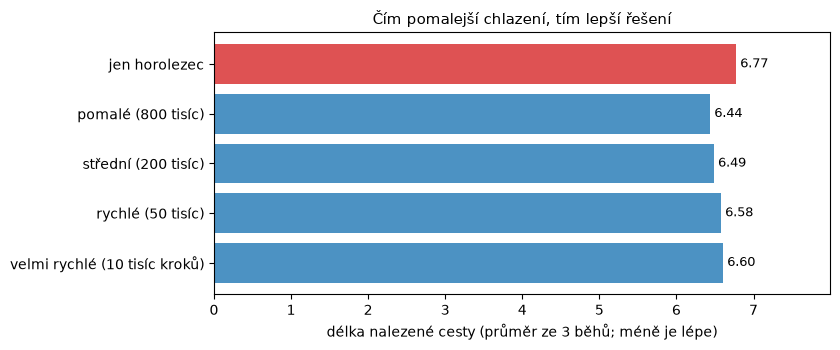

In [7]:
delky = {}
for nazev, kroku in (("velmi rychlé (10 tisíc kroků)", 10_000),
                     ("rychlé (50 tisíc)", 50_000),
                     ("střední (200 tisíc)", 200_000),
                     ("pomalé (800 tisíc)", 800_000)):
    vysledky = [zihani(mesta, kroku=kroku)[1] for _ in range(3)]
    delky[nazev] = sum(vysledky) / len(vysledky)

delky["jen horolezec"] = sum(vysl_hor) / BEHU

fig, ax = plt.subplots(figsize=(8.5, 3.6))
nazvy = list(delky)
hodnoty = [delky[n] for n in nazvy]
barvy = ["tab:red" if n == "jen horolezec" else "tab:blue" for n in nazvy]
b = ax.barh(nazvy, hodnoty, color=barvy, alpha=0.8)
ax.bar_label(b, fmt="%.2f", padding=3, fontsize=9)
ax.set_xlabel("délka nalezené cesty (průměr ze 3 běhů; méně je lépe)")
ax.set_xlim(0, max(hodnoty) * 1.18)
ax.set_title("Čím pomalejší chlazení, tím lepší řešení", fontsize=11)
plt.tight_layout()
plt.show()

## Shrnutí

| Pojem | Co si pamatovat |
|-------|-----------------|
| Monte Carlo algoritmus | rychlý, odpověď může být špatně s pravděpodobností, kterou si zvolíte |
| Las Vegas algoritmus | odpověď vždy správná, náhodná je doba běhu |
| Fermatův test | $a^{n-1}\equiv 1$; selhává na Carmichaelových číslech (561, 1105, 1729) |
| Miller–Rabin | využije i odmocniny z jedničky; u složeného $n$ je $\ge 3/4$ bází svědkem ⟹ chyba $\le 4^{-k}$ |
| Jednostranná chyba | „složené" je jisté, „prvočíslo" je pravděpodobné — a to stačí |
| Simulované žíhání | zhoršení o $\Delta E$ přijmi s pravděpodobností $e^{-\Delta E/T}$ |
| Teplota | vysoká = prozkoumávání, nízká = dolaďování; chladit postupně |
| Proč to funguje | horolezec uvázne v lokálním minimu, žíhání z něj umí vyskočit |

Hlavní rozdíl proti zbytku kurzu: tady náhoda **nic nemodeluje**. Je to nástroj, který nahrazuje výpočet, jenž by jinak trval neúnosně dlouho.

### Zkuste si

1. Pusťte Miller–Rabin s $k = 1$ na mnoho složených čísel a změřte, jak často se splete. Sedí mez $1/4$?
2. Najděte nejmenší složené číslo, které Miller–Rabin s pevnými bázemi $\{2, 3\}$ označí za prvočíslo. (Je to 1 373 653.)
3. Doplňte do žíhání jiný tah než 2-opt — třeba přesun jednoho města jinam. Zlepší se výsledek?
4. Nahraďte geometrické chlazení lineárním ($T_k = T_0(1 - k/K)$) a porovnejte. Které je lepší a proč?
5. Zkuste žíhání na jiné úloze: rozdělte $n$ čísel do dvou skupin se stejným součtem (problém rozdělení). Co je tam $\Delta E$ a co je tah?
6. Nastavte $T_0$ velmi nízko (třeba $10^{-6}$) a ověřte, že se žíhání chová přesně jako horolezec.